# CardioRisk Prediction

## Problem Statement

CardioCare, a healthcare provider, is committed to enhancing preventative care and improving patient outcomes. With the growing prevalence of cardiovascular disease (CVD), accurate and timely risk assessment is essential. Although CardioCare might provide comprehensive medical resources, optimising doctors' valuable consultation time is crucial for efficient and effective care. At the same time, correctly identifying at-risk patients is highly important.

### Business Objective

CardioCare aims to develop a machine learning model to predict CVD risk using patient health data. This model is intended to support healthcare providers in efficiently allocating resources and optimising doctors' consultation time. By identifying patients with high risk of CVD, the model can help prioritise consultations and potentially eliminate the need for an initial consultation stage for some patients. This will allow doctors to focus their expertise on individuals requiring immediate attention.

### Assignment Tasks

You need to perform the following steps to complete this assignment:
1. Data Understanding
2. Data Cleaning
3. Exploratory Data Analysis
4. Train Validation Split
5. Feature Engineering
6. Model Building
8. Prediction and Model Evaluation

**Based on this assignment, you have to answer the following questions:**

- What insights can we gain from exploring the relationships between different health metrics and the prevalence of cardiovascular disease within the patient population?

- Based on the analysis, which patient characteristics emerge as the strongest predictors of cardiovascular disease risk? Are there any surprising or unexpected findings?

- How effectively can machine learning models identify individuals at risk of developing cardiovascular disease based on their health data? How does the evaluation results vary across different models?

- How can CardioCare integrate the predictive model into their existing healthcare workflows to enhance preventative care strategies?

### Data Dictionary

The CardioRisk Prediction has 14 Columns and 70000 Rows. Following data dictionary provides the description for each column present in dataset:


<table>
  <tr>
    <th>Column Name</th>
    <th>Description</th>
  </tr>
  <tr>
    <td>Unnamed: 0</td>
    <td>Index or row number</td>
  </tr>
  <tr>
    <td>id</td>
    <td>Unique identifier for each individual in the dataset</td>
  </tr>
  <tr>
    <td>age</td>
    <td>Age of the individual, measured in days</td>
  </tr>
  <tr>
    <td>gender</td>
    <td>Gender of the individual (0: Female, 1: Male)</td>
  </tr>
  <tr>
    <td>height</td>
    <td>Height of the individual, measured in centimeters</td>
  </tr>
  <tr>
    <td>weight</td>
    <td>Weight of the individual, measured in kilograms</td>
  </tr>
  <tr>
    <td>ap_hi</td>
    <td>Systolic blood pressure reading</td>
  </tr>
  <tr>
    <td>ap_lo</td>
    <td>Diastolic blood pressure reading</td>
  </tr>
  <tr>
    <td>cholesterol</td>
    <td>Cholesterol level (0: normal, 1: above normal, 2: well above normal)</td>
  </tr>
  <tr>
    <td>gluc</td>
    <td>Glucose level (0: normal, 1: above normal, 2: well above normal)</td>
  </tr>
  <tr>
    <td>smoke</td>
    <td>Smoking status (0: No, 1: Yes)</td>
  </tr>
  <tr>
    <td>alco</td>
    <td>Alcohol intake status (0: No, 1: Yes)</td>
  </tr>
  <tr>
    <td>active</td>
    <td>Physical activity status (0: No, 1: Yes)</td>
  </tr>
  <tr>
    <td>cardio</td>
    <td>Presence or absence of cardiovascular disease (0: No Disease, 1: Disease)</td>
  </tr>
</table>

</body>
</html>


    
This data dictionary serves as a reference for understanding the dataset and its variables.

## **1. Data Understanding** 

<font color = red>[2 marks]</font> <br>

In this stage, you have to load the dataset and check basic statistics of the data, including preview of data, dimension of data, column descriptions and data types.

In [288]:
# suggested imports; import more libraries as needed
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, precision_recall_curve, \
    confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split, GridSearchCV
import warnings
warnings.filterwarnings('ignore')

### **1.1 Load the dataset**

<font color = red>[2 marks]</font> <br>

In [289]:
# Load the dataset
df = pd.read_csv('health_data.csv')
df.shape

(70000, 14)

#### **1.1.1** Check the first few entries

In [290]:
# Check the first few entries
df.head()

,Unnamed: 0,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0.0,18393.0,1,168.0,62.0,110.0,80.0,0,0,0,0,1,0
1,1,1.0,20228.0,0,156.0,85.0,140.0,90.0,2,0,0,0,1,1
2,2,2.0,18857.0,0,165.0,64.0,130.0,70.0,2,0,0,0,0,1
3,3,3.0,17623.0,1,169.0,82.0,150.0,100.0,0,0,0,0,1,1
4,4,4.0,17474.0,0,156.0,56.0,100.0,60.0,0,0,0,0,0,0


#### **1.1.2** Remove columns which are irrelevant <font color = red>[2 marks]</font> <br>

In [291]:
# Remove irrelevant columns like unique identifiers or index
df = df.drop(columns=['Unnamed: 0', 'id'])
df.head()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393.0,1,168.0,62.0,110.0,80.0,0,0,0,0,1,0
1,20228.0,0,156.0,85.0,140.0,90.0,2,0,0,0,1,1
2,18857.0,0,165.0,64.0,130.0,70.0,2,0,0,0,0,1
3,17623.0,1,169.0,82.0,150.0,100.0,0,0,0,0,1,1
4,17474.0,0,156.0,56.0,100.0,60.0,0,0,0,0,0,0


#### **1.1.3** Inspect the shape of the dataset

In [292]:
# Inspect the shape of the dataset
print(df.shape)

(70000, 12)


#### **1.1.4** Inspect the different columns in the dataset

In [293]:
# Inspect the different columns in the dataset
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          70000 non-null  float64
 1   gender       70000 non-null  int64  
 2   height       70000 non-null  float64
 3   weight       70000 non-null  float64
 4   ap_hi        70000 non-null  float64
 5   ap_lo        70000 non-null  float64
 6   cholesterol  70000 non-null  int64  
 7   gluc         70000 non-null  int64  
 8   smoke        70000 non-null  int64  
 9   alco         70000 non-null  int64  
 10  active       70000 non-null  int64  
 11  cardio       70000 non-null  int64  
dtypes: float64(5), int64(7)
memory usage: 6.4 MB


Index(['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

Check the summary of the dataset

In [294]:
# Check the summary of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          70000 non-null  float64
 1   gender       70000 non-null  int64  
 2   height       70000 non-null  float64
 3   weight       70000 non-null  float64
 4   ap_hi        70000 non-null  float64
 5   ap_lo        70000 non-null  float64
 6   cholesterol  70000 non-null  int64  
 7   gluc         70000 non-null  int64  
 8   smoke        70000 non-null  int64  
 9   alco         70000 non-null  int64  
 10  active       70000 non-null  int64  
 11  cardio       70000 non-null  int64  
dtypes: float64(5), int64(7)
memory usage: 6.4 MB


## **2. Data Cleaning** 

<font color = red>[8 marks]</font> <br>

### **2.1 Identify and handle redundant or invalid/illogical physiological values** 

<font color = red>[6 marks]</font> <br>

Examine the dataset to identify any columns containing data points that are invalid, illogical, or fall outside of typical physiological ranges.

- Pay attention to blood pressure values and ensure they fall within reasonable physiological limits. Very high or low values might need to be investigated or addressed. Blood pressure values less than 30 and more than 300 are rarely observed.
- Additionally, think about which unit might be more intuitive for understanding a person's age in a healthcare context.
- Similarly, reflect on the representation of height and explore whether using a different unit would align better with typical practices in healthcare and enhance the overall interpretability of the data.

#### **2.1.1** Check the statistical summary of the data <font color = red>[1 marks]</font> <br>

Examine the statistical summary to identify the columns containing data points that are invalid, illogical, or fall outside of typical physiological ranges.

In [295]:
# Check the statistical summary of the data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,70000.0,19468.865814,2467.251667,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,0.349571,0.476838,0.0,0.0,0.0,1.0,1.0
height,70000.0,164.359229,8.210126,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.205690,14.395757,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,0.366871,0.680250,0.0,0.0,0.0,1.0,2.0
gluc,70000.0,0.226457,0.572270,0.0,0.0,0.0,0.0,2.0
smoke,70000.0,0.088129,0.283484,0.0,0.0,0.0,0.0,1.0
alco,70000.0,0.053771,0.225568,0.0,0.0,0.0,0.0,1.0


#### **2.1.2** Handle rows with invalid/illogical values <font color = red>[3 marks]</font> <br>

Based on the details of data present in statistical summary, handle the columns that have invalid/illogical values or does not fall within physiological limits or have extreme values.

In [296]:
# # Handle rows which have invalid or illogical values or does not fall within physiological limits (include extreme cases) for blood pressure and height etc
# # Blood pressure: Diastolic pressure (ap_lo) should always be lower than
# # systolic pressure (ap_hi). Values outside the 30–300 mmHg range are
# # considered physiologically implausible and are typically treated as invalid.
# # checking the stats about standard deviation and mean of the columns -- ap_hi and ap_lo seems to have some errors

# bp_mask = (
#     (df['ap_hi'].between(30, 300)) &
#     (df['ap_lo'].between(30, 300)) &
#     (df['ap_lo'] <= df['ap_hi'])
# )

# print(f"Invalid blood pressure rows removed: {(~bp_mask).sum()}")

# df = df[bp_mask]

# # Height/weight: Remove unusually low or high values. 
# # 55 cm and 250 cm are highly unusual for an adult dataset. 10 kg → almost certainly invalid for an adult. 00 kg → very high, but not necessarily impossible. A person can weigh 200 kg.

# df = df[
#     (df['height'] >= 100) &
#     (df['height'] <= 220) &
#     (df['weight'] >= 30) &
#     (df['weight'] <= 300)
# ]

# print(df[['height', 'weight', 'ap_hi', 'ap_lo']].describe())
# df = df.reset_index(drop=True)
# print(f"Rows after cleaning: {df.shape[0]}")


# Handle rows which have invalid or illogical values or does not fall within physiological limits (include extreme cases) for blood pressure and height etc
print(f"Rows before cleaning: {df.shape[0]}")

# Blood pressure: diastolic (ap_lo) cannot logically exceed systolic (ap_hi), and values
# outside 30-300 mmHg are essentially never observed physiologically
bp_mask = (df['ap_hi'].between(30, 300)) & (df['ap_lo'].between(30, 300)) & (df['ap_lo'] <= df['ap_hi'])
print(f"Invalid blood pressure rows removed: {(~bp_mask).sum()}")
df = df[bp_mask]

# Height/weight: remove extreme, physiologically implausible values using the
# 0.25th and 99.75th percentiles as cutoffs (data-driven trimming of outliers)
h_low, h_high = df['height'].quantile([0.0025, 0.9975])
w_low, w_high = df['weight'].quantile([0.0025, 0.9975])
print(f"Height bounds: {h_low:.1f}-{h_high:.1f} cm, Weight bounds: {w_low:.1f}-{w_high:.1f} kg")
hw_mask = df['height'].between(h_low, h_high) & df['weight'].between(w_low, w_high)
print(f"Extreme height/weight rows removed: {(~hw_mask).sum()}")
df = df[hw_mask]

df = df.reset_index(drop=True)
print(f"Rows after cleaning: {df.shape[0]}")

print(df[['height', 'weight', 'ap_hi', 'ap_lo']].describe())


Rows before cleaning: 70000
Invalid blood pressure rows removed: 1320
Height bounds: 140.0-188.0 cm, Weight bounds: 42.0-132.3 kg
Extreme height/weight rows removed: 563
Rows after cleaning: 68117
             height        weight         ap_hi         ap_lo
count  68117.000000  68117.000000  68117.000000  68117.000000
mean     164.417399     73.974771    126.661333     81.298897
std        7.690991     13.747748     16.656838      9.441719
min      140.000000     42.000000     60.000000     30.000000
25%      159.000000     65.000000    120.000000     80.000000
50%      165.000000     72.000000    120.000000     80.000000
75%      170.000000     82.000000    140.000000     90.000000
max      188.000000    132.000000    240.000000    182.000000


#### **2.1.3** Modify the representation of patient age and height <font color = red>[2 marks]</font> <br>

In [297]:
# Modify the representation of patient age and height (to years and meters) for better understanding in a healthcare context

df['age'] = (df['age'] / 365.25).round(1)      # days -> years
df['height'] = (df['height'] / 100).round(3)   # cm -> m

df[['age', 'height']].describe()



,age,height
count,68117.000000,68117.000000
mean,53.297275,1.644174
std,6.754548,0.076910
min,29.600000,1.400000
25%,48.400000,1.590000
50%,53.900000,1.650000
75%,58.400000,1.700000
max,64.900000,1.880000


### **2.2 Fix DataTypes** 

<font color = red>[2 marks]</font> <br>

#### **2.2.1** Review and fix the data types of all columns <font color = red>[2 marks]</font> <br>

Ensuring the columns accurately reflect the nature of the data 

In [298]:
# Fix DataTypes of the categorical columns with incorrect DataTypes
categorical_cols = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
for col in categorical_cols:
    df[col] = df[col].astype('category')


In [299]:
# Check the final data types post conversion
df.dtypes

age             float64
gender         category
height          float64
weight          float64
ap_hi           float64
ap_lo           float64
cholesterol    category
gluc           category
smoke          category
alco           category
active         category
cardio         category
dtype: object

## **3. Exploratory Data Analysis** 

<font color = red>[27 marks]</font>

### **3.1 Perform univariate analysis** 

<font color = red>[12 marks]</font>

#### **3.1.1** Visualise the numerical features <font color = red>[5 marks]</font>

Visualise the distribution of numerical features using appropriate plots to understand their characteristics.

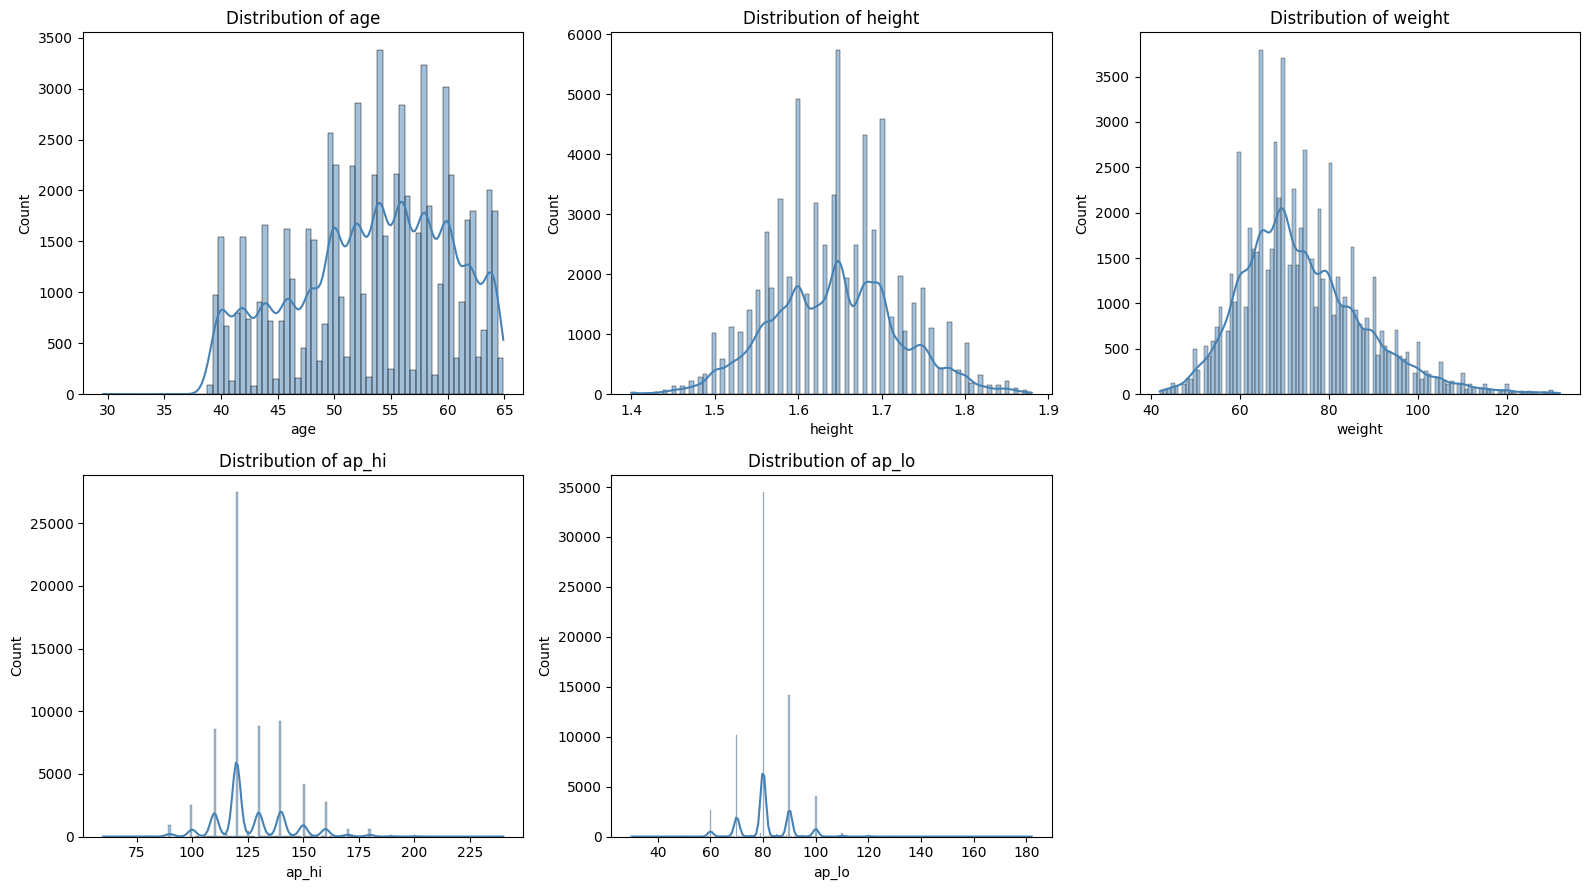

In [300]:
# Plot all the numerical columns to understand their distribution
num_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
fig.delaxes(axes.flat[-1])
plt.tight_layout()
plt.show()


#### **3.1.2** Visualise the categorical features <font color = red>[5 marks]</font>

Visualise the distribution of categorical features to get a clear view of the data distribution across various categories. This will help in identifying potential imbalances or dominant categories.

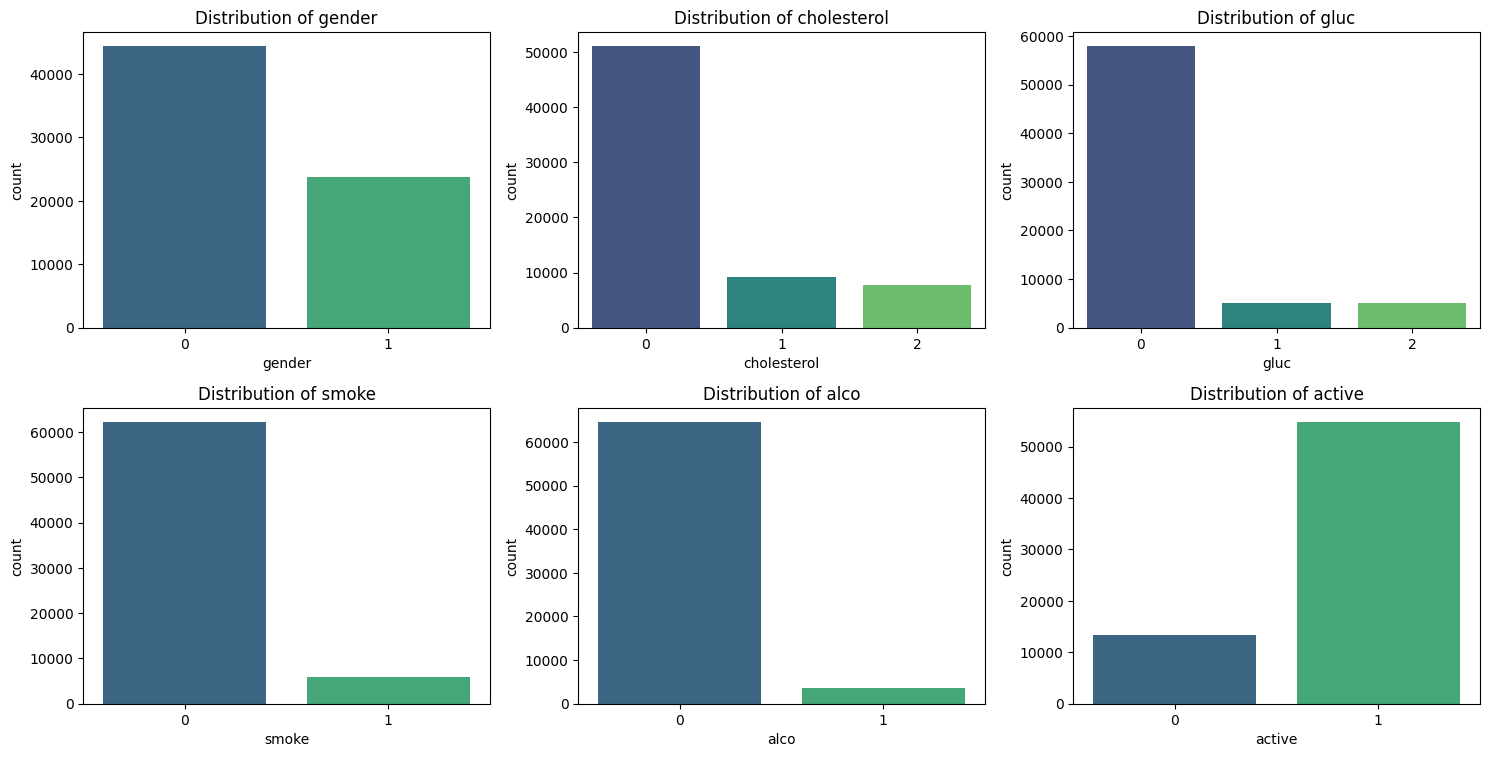

In [301]:
# Select and plot categorical columns
cat_cols_plot = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, cat_cols_plot):
    sns.countplot(x=df[col], hue=df[col], ax=ax, palette='viridis', legend=False)
    ax.set_title(f'Distribution of {col}')
for ax in axes.flat[len(cat_cols_plot):]:
    fig.delaxes(ax)
plt.tight_layout()
plt.show()


#### **3.1.3** Check class distribution of the target feature <font color = red>[2 marks]</font>

cardio
0    34433
1    33684
Name: count, dtype: int64
cardio
0    50.55
1    49.45
Name: proportion, dtype: float64


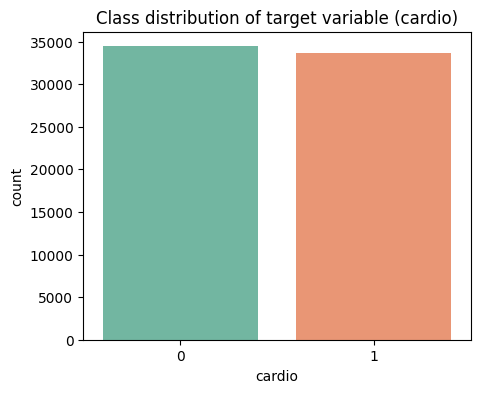

In [302]:
# Class distribution of positive and negative classes
print(df['cardio'].value_counts())
print((df['cardio'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x=df['cardio'], hue=df['cardio'], palette='Set2', legend=False)
plt.title('Class distribution of target variable (cardio)')
plt.show()

### **3.2 Perform correlation analysis** 

<font color = red>[5 marks]</font>

Investigate the relationships between numerical features to identify potential multicollinearity or dependencies. Visualise the correlation structure using an appropriate method to gain insights into feature relationships 

#### **3.2.1** Visualise the correlation among numerical features <font color="red">[5 Marks]</font>


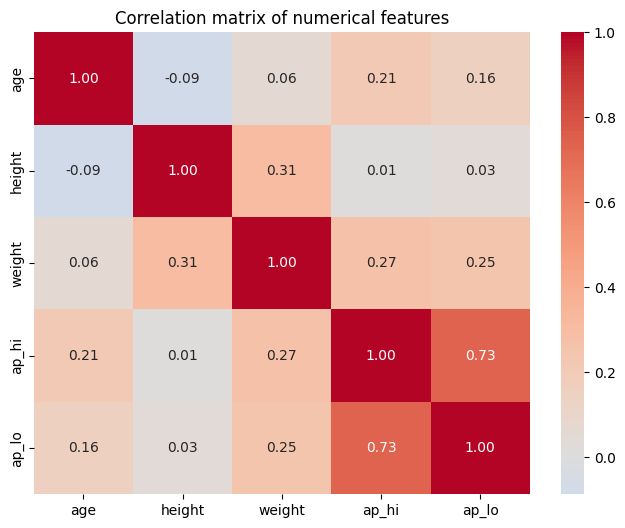

In [303]:
# Plot Heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix of numerical features')
plt.show()


### **3.3 Perform bivariate analysis** 

<font color = red>[10 marks]</font>

#### **3.3.1** Analyse categorical features <font color="red">[5 Marks]</font>

For each categorical feature (excluding the target), calculate the proportion of `cardio = 1` in each category of the feature. Use this to identify which categorical features show clear differences in heart disease likelihood and which are less informative.

In [304]:
# Write a function to analyse the target variable likelihood for categorical features
def cardio_rate_by_category(data, column, target='cardio'):
    """Return the proportion of cardio=1 for each category of `column`."""
    return data.groupby(column, observed=True)[target].apply(lambda s: s.astype(int).mean())

categorical_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

for col in categorical_features:
    print(f"\nCardio=1 rate by {col}:")
    print(cardio_rate_by_category(df, col))



Cardio=1 rate by gender:
gender
0    0.492151
1    0.498904
Name: cardio, dtype: float64

Cardio=1 rate by cholesterol:
cholesterol
0    0.435166
1    0.596877
2    0.761716
Name: cardio, dtype: float64

Cardio=1 rate by gluc:
gluc
0    0.475609
1    0.587238
2    0.616248
Name: cardio, dtype: float64

Cardio=1 rate by smoke:
smoke
0    0.497063
1    0.467850
Name: cardio, dtype: float64

Cardio=1 rate by alco:
alco
0    0.495527
1    0.476256
Name: cardio, dtype: float64

Cardio=1 rate by active:
active
0    0.532586
1    0.485193
Name: cardio, dtype: float64


#### **3.3.2** Explore the relationships between numerical features and the target variable <font color = red>[5 marks]</font>

Understand the impact of numeric features on the target outcome using appropriate visualisation techniques to identify trends and potential interactions

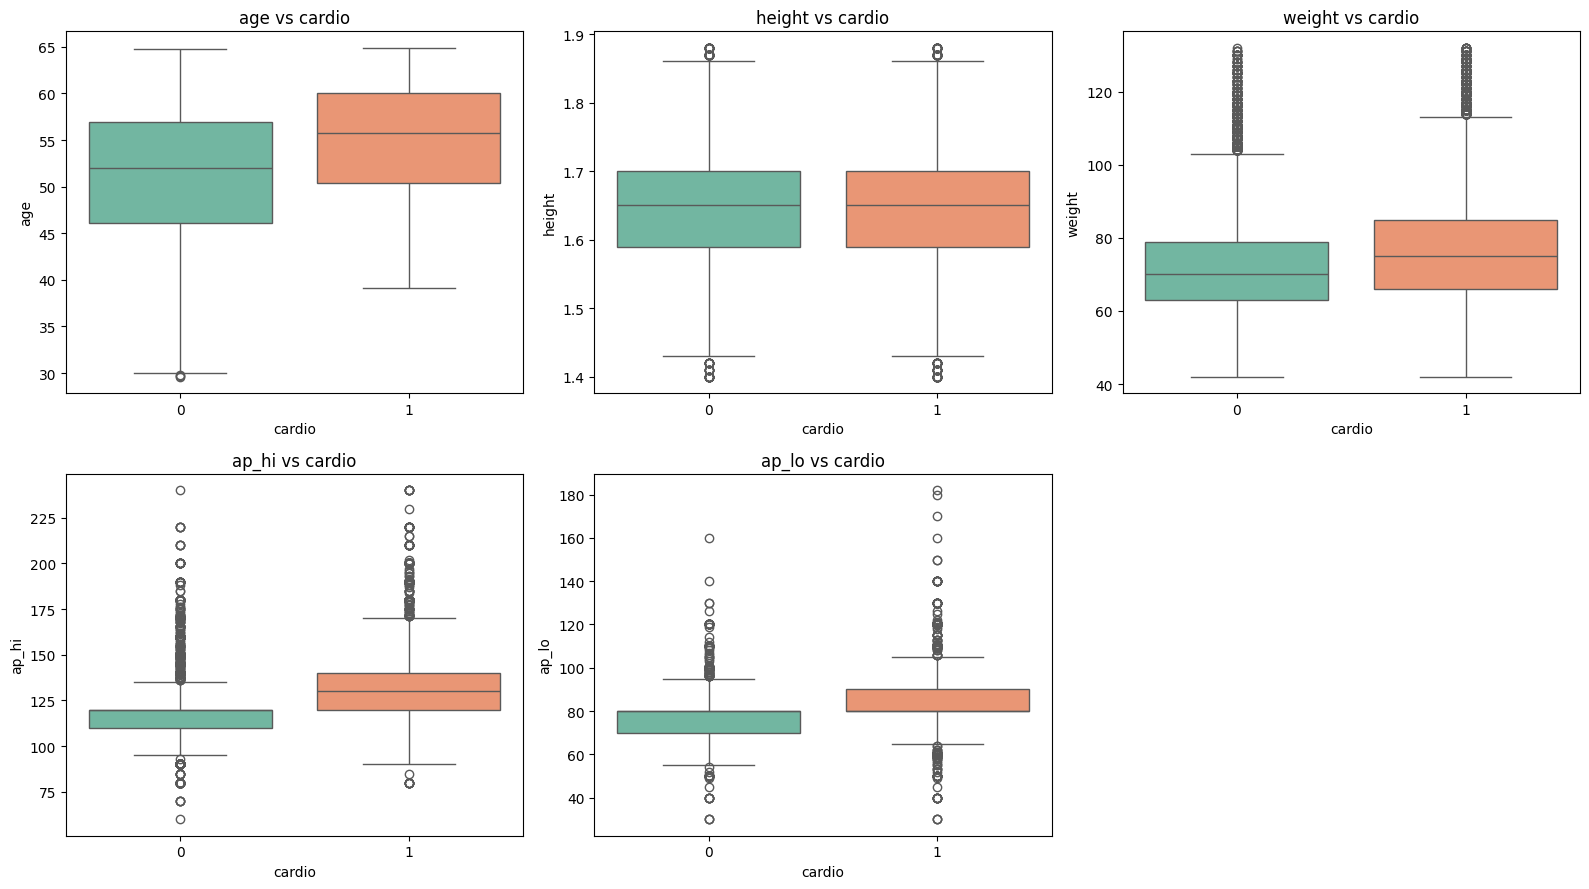

In [305]:
# Plot distribution for each numerical column with target variable
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df['cardio'], y=df[col], hue=df['cardio'], ax=ax, palette='Set2', legend=False)
    ax.set_title(f'{col} vs cardio')
fig.delaxes(axes.flat[-1])
plt.tight_layout()
plt.show()


## **4. Train-Test Split** 

<font color = red>[5 marks]</font>

### **4.1 Data Splitting** 

<font color = red>[5 Marks]</font>

#### **4.1.1** Define feature and target variables <font color = red>[2 Marks]</font>

In [306]:
# Put all the feature variables in X and target in y
X = df.drop(columns='cardio')
y = df['cardio'].astype(int)

#### **4.1.2** Split the data into train and test sets <font color="red">[3 Marks]</font>

Split the data in 0.7:0.3 sets. and reset the index for the sets. Check the shape of the test and test sets.


In [307]:
#  Split the data into 70% train data and 30% test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=42, stratify=y
)
print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (47681, 11)  X_test: (20436, 11)


In [308]:
# Reset index for all train and test sets
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


## **5. Feature Engineering** 

<font color = red>[18 marks]</font>

### **5.1 Create a new feature** 

<font color = red>[6 marks]</font>

#### **5.1.1** Create a new feature `BMI` (Body Mass Index) <font color="red">[3 Marks]</font>

BMI is a standard health metric calculated using a person's height and weight. BMI is known to be a useful predictor for cardiovascular risk.

In [309]:
# Create a new feature 'BMI'
X_train['bmi'] = X_train['weight'] / (X_train['height'] ** 2)
X_test['bmi'] = X_test['weight'] / (X_test['height'] ** 2)
X_train[['weight', 'height', 'bmi']].head()


,weight,height,bmi
0,70.0,1.65,25.711662
1,88.0,1.63,33.121307
2,70.0,1.68,24.801587
3,63.0,1.58,25.236340
4,60.0,1.55,24.973985


**Note:** Feel free to engineer more features if you wish to.

#### **5.1.2** Perform correlation analysis  <font color="red">[3 Marks]</font>

After creating the new feature `BMI`, perform correlation analysis to check if it's correlated with any existing features. Perform suitable processing steps if high correlation is found.

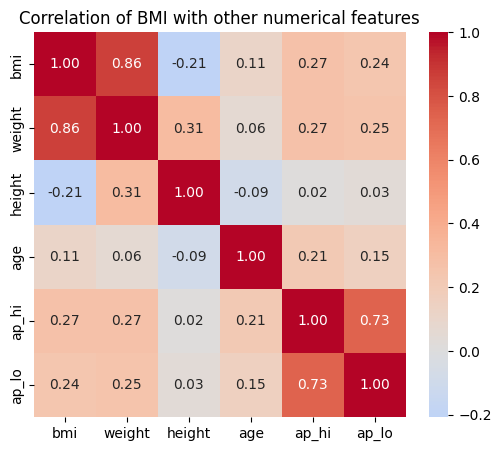

In [310]:
# Plot check correlation 
corr_with_bmi = X_train[['bmi', 'weight', 'height', 'age', 'ap_hi', 'ap_lo']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_with_bmi, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of BMI with other numerical features')
plt.show()


In [311]:
# Did you find any highly correlated features? What steps should you take
# BMI is strongly correlated with weight (~0.86), which is expected since BMI is derived
# directly from weight and height. Keeping both weight and BMI would inject redundant,
# highly-collinear information into the models, so we drop the original 'weight' column
# and retain the engineered 'bmi' feature (height is only weakly correlated with BMI and
# still carries independent information, so we keep it).
X_train = X_train.drop(columns=['weight'])
X_test = X_test.drop(columns=['weight'])
print(X_train.columns.tolist())


['age', 'gender', 'height', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi']


### **5.2 Combine Values in Categorical Columns** 

<font color="red">[4 Marks]</font>

#### **5.2.1** Combine Low-Frequency Categories <font color="red">[4 Marks]</font>

During the EDA process, categorical columns with multiple unique levels may be identified. To enhance model performance, it is recommended to refine these categorical features by grouping values that have low frequency or provide limited predictive information.

Combine categories that occur infrequently or exhibit similar behavior to reduce sparsity and improve model generalisation.

In [312]:
# # Combine categories that have low frequency or provide limited predictive information such as gluc and cholesterol
# # 1. Get raw counts
# counts = pd.crosstab(df["gluc"], df["cardio"])

# # 2. Get percentages (rounded to 1 decimal place)
# pcts = pd.crosstab(df["gluc"], df["cardio"], normalize="index") * 100
# pcts = pcts.round(1)

# # 3. Combine them side-by-side with clear headers
# summary_df = pd.concat([counts, pcts], axis=1, keys=["Count", "Percentage (%)"])
# print(summary_df)

# # Get the percentage breakdown of the gluc column itself
# gluc_pct = X_train["gluc"].value_counts(normalize=True).mul(100).round(1)

# # Convert to a clean DataFrame for readability
# gluc_summary = pd.DataFrame(
#     {"Count": X_train["gluc"].value_counts(), "Total Percentage (%)": gluc_pct}
# )
# print(gluc_summary)

for dataset in (X_train, X_test):
    dataset['gluc'] = dataset['gluc'].astype(int).map({0: 0, 1: 1, 2: 1}).astype('category')
    dataset['cholesterol'] = dataset['cholesterol'].astype('category')

### **5.3 Dummy variable creation** 

<font color = red>[5 marks]</font>

#### **5.3.1** Create dummy variables for categorical columns <font color="red">[5 Mark]</font>

In [313]:
# Identify the columns for creating dummy variables
dummy_cols = ['cholesterol', 'gluc']
print("Columns to be dummy-encoded:", dummy_cols)


Columns to be dummy-encoded: ['cholesterol', 'gluc']


In [314]:
# Create dummy variables for independent columns on training data
X_train = pd.get_dummies(X_train, columns=dummy_cols, drop_first=True)
X_train.head()


,age,gender,height,ap_hi,ap_lo,smoke,alco,active,bmi,cholesterol_1,cholesterol_2,gluc_1
0,40.7,1,1.65,120.0,80.0,0,0,1,25.711662,False,False,False
1,61.5,0,1.63,140.0,90.0,0,0,1,33.121307,False,True,False
2,50.1,0,1.68,110.0,70.0,0,0,1,24.801587,False,False,False
3,41.9,0,1.58,90.0,60.0,0,0,1,25.236340,False,False,False
4,40.0,0,1.55,110.0,80.0,0,0,1,24.973985,False,False,False


In [315]:
# Create dummy variables for independent columns on test data
X_test = pd.get_dummies(X_test, columns=dummy_cols, drop_first=True)
# Ensure test set has exactly the same columns (and order) as the train set
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_test.head()

,age,gender,height,ap_hi,ap_lo,smoke,alco,active,bmi,cholesterol_1,cholesterol_2,gluc_1
0,62.2,1,1.76,110.0,70.0,0,0,1,23.243802,False,False,False
1,56.8,0,1.52,120.0,80.0,0,0,1,27.700831,False,False,False
2,55.5,0,1.65,120.0,80.0,0,0,0,23.875115,False,False,False
3,58.3,0,1.65,140.0,90.0,0,0,1,23.875115,True,False,False
4,57.8,0,1.55,140.0,90.0,0,0,0,28.720083,False,True,False


### **5.4 Feature scaling** 

<font color = red>[3 marks]</font>

#### **5.4.1** Scale numerical features <font color = red>[3 marks]</font>

Choose a scaling method appropriate for the data and the chosen model. Apply the same scaling to both training and test data.

In [316]:
for col in X_train.columns:
    if str(X_train[col].dtype) in ('category', 'bool'):
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
        
# Scale the numeric features present in the training data

num_scale_cols = ['age', 'height', 'ap_hi', 'ap_lo', 'bmi']
scaler = MinMaxScaler()
X_train[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])


# Scale the numerical features present in the test data
X_test[num_scale_cols] = scaler.transform(X_test[num_scale_cols])




In [317]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,47681.0,0.671050,0.191047,0.0,0.529745,0.688385,0.815864,1.0
gender,47681.0,0.349133,0.476701,0.0,0.000000,0.000000,1.000000,1.0
height,47681.0,0.509543,0.160270,0.0,0.395833,0.520833,0.625000,1.0
ap_hi,47681.0,0.333394,0.097797,0.0,0.294118,0.294118,0.411765,1.0
ap_lo,47681.0,0.341930,0.062736,0.0,0.333333,0.333333,0.400000,1.0
smoke,47681.0,0.088106,0.283453,0.0,0.000000,0.000000,0.000000,1.0
alco,47681.0,0.052662,0.223361,0.0,0.000000,0.000000,0.000000,1.0
active,47681.0,0.802248,0.398308,0.0,1.000000,1.000000,1.000000,1.0
bmi,47681.0,0.260029,0.101646,0.0,0.189042,0.238050,0.315137,1.0
cholesterol_1,47681.0,0.136323,0.343134,0.0,0.000000,0.000000,0.000000,1.0


## **6. Model Building** 

<font color = red>[38 marks]</font>

In this task, you will build the two machine learning models: Support Vector Classifier (SVC) and a Decision Tree classifier. We will follow the same structured workflow for the models:

* *Model Building and Initial Evaluation*: <br> Fit the model and evaluate its performance on the training data using the default cutoff
* *Find the Optimal Cutoff*: <br> Determine the best probability threshold using sensitivity-specificity and precision–recall trade-offs
* *Model Prediction & Evaluation using chosen cutoff*: <br> Generate predictions using the chosen cutoff and evaluate performance on the training data
* *Hyperparameter Tuning (Grid Search)*: <br> Optimise performance using grid search for hyperparameter tuning
* *Final Model Training & Evaluation using chosen cutoff*: <br> Train the final model using the best hyperparameters and evaluate performance on the training data

### **6.1 SVM Classifier** 

<font color = red>[18 marks]</font>

#### **6.1.1** Define a Linear SVM classifier and fit it on the train set <font color = red>[2 mark]</font>

Go through the [SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC) and define a model with linear kernel that will also return the probabilities estimates of the predictions.

In [318]:
# Define and fit linear SVM
from sklearn.utils import resample

SVM_SAMPLE_SIZE = 8000
X_train_svm, y_train_svm = resample(
    X_train, y_train, n_samples=SVM_SAMPLE_SIZE, stratify=y_train, random_state=42
)

svm_linear = SVC(kernel='linear', probability=True, random_state=42)
svm_linear.fit(X_train_svm, y_train_svm)


SVC(kernel='linear', probability=True, random_state=42)

#### **6.1.2** Get the probability estimates on test set and predict class using a threshold <font color = red>[3 mark]</font>

We defined the model to also return the probabilities after training. Use the `SVC.predict_proba()`[(documentation)](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC.predict_proba) function to fetch the probabilities on test set. For each sample, it returns the probabilities of each class in a sorted order (according to `SVC.classes_`)

After getting the probability values, assign class labels using the default threshold of 0.5 and check the distribution of assigned labels.

In [319]:
# Use predict_proba() to get the probability of positive class for all data points
train_proba_svm = svm_linear.predict_proba(X_train)[:, 1]
train_proba_svm[:10]


array([0.22742675, 0.91295161, 0.19992178, 0.05585894, 0.15307818,
       0.40652928, 0.22931775, 0.34529955, 0.51254285, 0.47704632])

In [320]:
# Make class predictions based on default cutoff value of 0.5 on testing data
train_pred_svm_proba_based = (train_proba_svm >= 0.5).astype(int)


In [321]:
# check the counts of assigned labels
pd.Series(train_pred_svm_proba_based).value_counts()

0    26981
1    20700
Name: count, dtype: int64

#### **6.1.3** Predict the class labels using the `predict()` function <font color = red>[2 mark]</font>

Now, directly use the `predict()` function to predict the class labels and check the distribution of assigned labels using this method.

In [322]:
# Make class predictions using predict()
train_pred_svm_predict = svm_linear.predict(X_train)

In [323]:
# check the counts of assigned labels
pd.Series(train_pred_svm_predict).value_counts()

0    28305
1    19376
Name: count, dtype: int64

Did you find any difference in the distribution of classes in the predictions using these two methods? Why do you think that is?

Try going through the documentation of `predict_proba()` linked above.

#### **6.1.4** Calculate performance metrics for both the above methods <font color = red>[3 mark]</font>

Calculate the performance metrics for both `predict_proba()` and `predict()` estimates. Compare the results and choose one to continue ahead.

In [324]:
# check the performance for above two methods
print("=== SVM: predict_proba() @ 0.5 cutoff (TRAIN) ===")
print(classification_report(y_train, train_pred_svm_proba_based))

print("\n=== SVM: predict() (TRAIN) ===")
print(classification_report(y_train, train_pred_svm_predict))

=== SVM: predict_proba() @ 0.5 cutoff (TRAIN) ===
              precision    recall  f1-score   support

           0       0.71      0.79      0.75     24103
           1       0.76      0.67      0.71     23578

    accuracy                           0.73     47681
   macro avg       0.73      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681


=== SVM: predict() (TRAIN) ===
              precision    recall  f1-score   support

           0       0.70      0.82      0.75     24103
           1       0.77      0.64      0.70     23578

    accuracy                           0.73     47681
   macro avg       0.74      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681



#### **6.1.5** Plot the ROC curve <font color="red">[2 Marks]</font>

Find the optimal cutoff to improve model performance by evaluating various cutoff values and their impact on relevant metrics. Plot ROC Curve to visualise the trade-off between true positive rate and false positive rate across different classification thresholds.

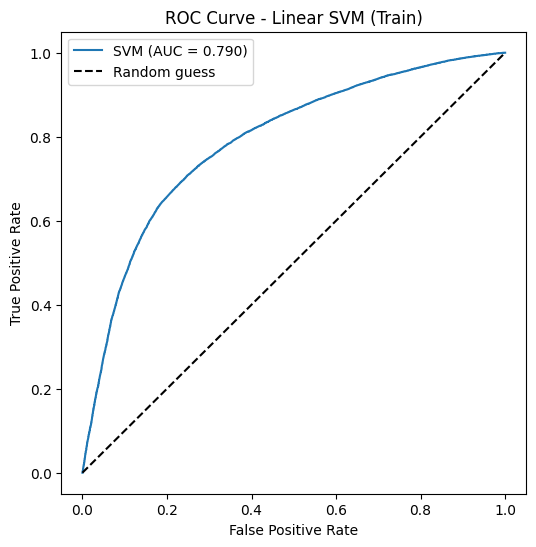

Train AUC: 0.79


In [325]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_train, train_proba_svm)
auc_svm = roc_auc_score(y_train, train_proba_svm)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'SVM (AUC = {auc_svm:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Linear SVM (Train)')
plt.legend()
plt.show()

print("Train AUC:", round(auc_svm, 4))


#### **6.1.6** Plot for accuracy, sensitivity, specificity at different probability cutoffs <font color="red">[3 Marks]</font>

In [326]:
# Create a DataFrame to see the values of accuracy, sensitivity, and specificity at different values of probability cutoffs

cutoff_prob_df = pd.DataFrame(columns=['prob', 'accuracy', 'sensitivity', 'specificity'])
cutoffs = np.arange(0.0, 1.0, 0.05)

for i, cutoff in enumerate(cutoffs):
    pred = (train_proba_svm >= cutoff).astype(int)
    cm = confusion_matrix(y_train, pred)
    total = cm.sum()
    accuracy = (cm[0, 0] + cm[1, 1]) / total
    sensitivity = cm[1, 1] / (cm[1, 0] + cm[1, 1])
    specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])
    cutoff_prob_df.loc[i] = [cutoff, accuracy, sensitivity, specificity]

cutoff_prob_df

,prob,accuracy,sensitivity,specificity
0,0.00,0.494495,1.000000,0.000000
1,0.05,0.495837,0.999958,0.002697
2,0.10,0.509973,0.996522,0.034021
3,0.15,0.533504,0.989142,0.087790
4,0.20,0.564019,0.974510,0.162469
5,0.25,0.603364,0.948511,0.265735
6,0.30,0.646085,0.907414,0.390449
7,0.35,0.686164,0.854780,0.521221
8,0.40,0.718819,0.782212,0.656806
9,0.45,0.729074,0.714776,0.743061


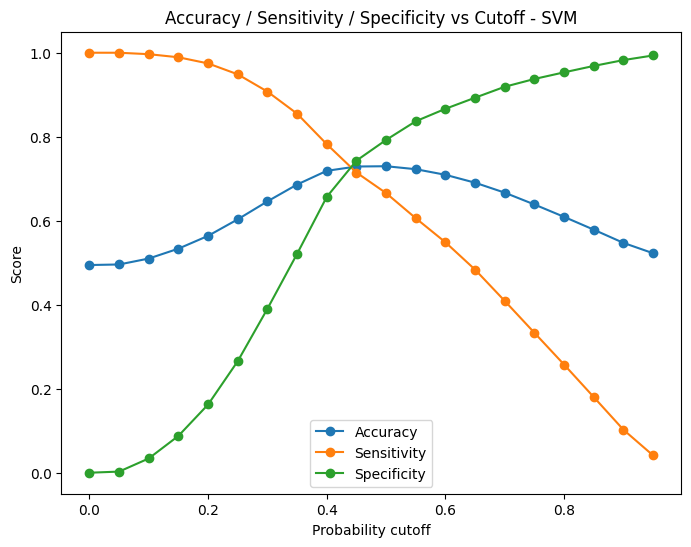

Optimal cutoff (sensitivity-specificity intersection): 0.45


In [327]:
# Plot accuracy, sensitivity, and specificity at different values of probability cutoffs stored in DF
plt.figure(figsize=(8, 6))
plt.plot(cutoff_prob_df['prob'], cutoff_prob_df['accuracy'], label='Accuracy', marker='o')
plt.plot(cutoff_prob_df['prob'], cutoff_prob_df['sensitivity'], label='Sensitivity', marker='o')
plt.plot(cutoff_prob_df['prob'], cutoff_prob_df['specificity'], label='Specificity', marker='o')
plt.xlabel('Probability cutoff')
plt.ylabel('Score')
plt.title('Accuracy / Sensitivity / Specificity vs Cutoff - SVM')
plt.legend()
plt.show()

diffs = (cutoff_prob_df['sensitivity'] - cutoff_prob_df['specificity']).abs()
optimal_cutoff_svm = float(cutoff_prob_df.loc[diffs.idxmin(), 'prob'])
print("Optimal cutoff (sensitivity-specificity intersection):", optimal_cutoff_svm)


To minimise the risk of missing high cardiovascular risk individuals, we should prioritise our model's ability to correctly identify those with cardiovascular disease.

#### **6.1.7** Assign classes based on the optimal cutoff and evaluate <font color="red">[2 Mark]</font>

Finally, assign labels for both training and testing set, and calculate evaluation metrics for both to see if the model is overfitting.

In [328]:
# Make final prediction based on the optimal cutoff
train_pred_svm_final = (train_proba_svm >= optimal_cutoff_svm).astype(int)
test_proba_svm = svm_linear.predict_proba(X_test)[:, 1]
test_pred_svm_final = (test_proba_svm >= optimal_cutoff_svm).astype(int)


In [329]:
# Evaluate the model performance 
print("=== SVM Performance @ optimal cutoff -- TEST ===")
print(classification_report(y_test, test_pred_svm_final))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_svm), 4))

=== SVM Performance @ optimal cutoff -- TEST ===
              precision    recall  f1-score   support

           0       0.72      0.73      0.73     10330
           1       0.72      0.71      0.72     10106

    accuracy                           0.72     20436
   macro avg       0.72      0.72      0.72     20436
weighted avg       0.72      0.72      0.72     20436

Test AUC: 0.7876


In [330]:
# Check performance on training data
print("=== SVM Performance @ optimal cutoff -- TRAIN ===")
print(classification_report(y_train, train_pred_svm_final))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_svm), 4))



=== SVM Performance @ optimal cutoff -- TRAIN ===
              precision    recall  f1-score   support

           0       0.73      0.74      0.73     24103
           1       0.73      0.71      0.72     23578

    accuracy                           0.73     47681
   macro avg       0.73      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681

Train AUC: 0.79


#### **6.1.8** Plot precision-recall curve <font color="red">[1 Mark]</font>

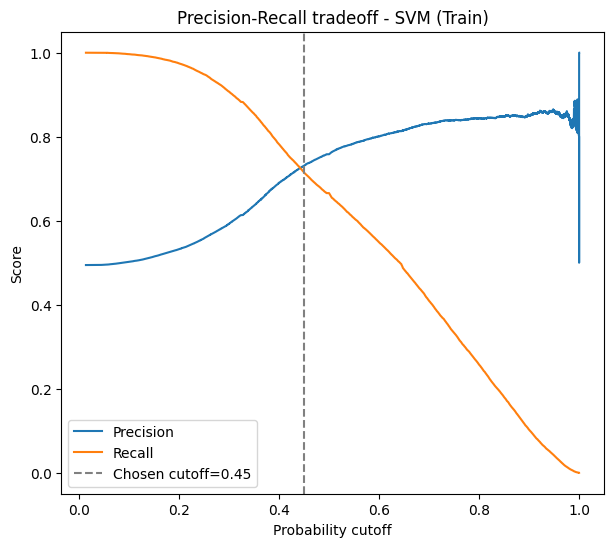

In [331]:
# Compute precision–recall values and plot for various thresholds
precision, recall, pr_thresholds = precision_recall_curve(y_train, train_proba_svm)

plt.figure(figsize=(7, 6))
plt.plot(pr_thresholds, precision[:-1], label='Precision')
plt.plot(pr_thresholds, recall[:-1], label='Recall')
plt.axvline(optimal_cutoff_svm, color='grey', linestyle='--', label=f'Chosen cutoff={optimal_cutoff_svm}')
plt.xlabel('Probability cutoff')
plt.ylabel('Score')
plt.title('Precision-Recall tradeoff - SVM (Train)')
plt.legend()
plt.show()


Since we want to prioritise recall/sensitivity over precision to minimise the risk of missing high-risk individuals, we can choose an agreeable cutoff value.

### **6.2 Decision Tree Classifier** 

<font color = red>[12 marks]</font>

#### **6.2.1** Define a Decision Tree classifier and fit it on the train set <font color = red>[1 mark]</font>

In [332]:
# Define and fit
dt_default = DecisionTreeClassifier(random_state=42)
dt_default.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

#### **6.2.2** Get feature importance scores <font color = red>[2 Marks]</font>

In [333]:
# Get feature importance scores from the trained model
feat_importance_default = pd.Series(
    dt_default.feature_importances_, index=X_train.columns
).sort_values(ascending=False)
feat_importance_default


bmi              0.246589
ap_hi            0.232855
age              0.230633
height           0.139310
ap_lo            0.044252
gender           0.023061
cholesterol_2    0.021339
active           0.016036
gluc_1           0.014572
cholesterol_1    0.013860
smoke            0.010429
alco             0.007064
dtype: float64

#### **6.2.3** Predict the class probabilities on the test set <font color="red">[1 Mark]</font>

Use `predict_proba()` to get the probability estimates

In [334]:
# Predict the class probabilities
train_proba_dt = dt_default.predict_proba(X_train)[:, 1]


####  **6.2.4** Make prediction based on default cutoff value of 0.5 on testing data <font color = "red">[1 Mark]</font>

In [335]:
# Make prediction based on default cutoff value of 0.5
train_pred_dt_default = (train_proba_dt >= 0.5).astype(int)


####  **6.2.5** Evaluate the performance of the model <font color = "red">[1 Mark]</font>

In [336]:
# Evaluate the performance of the model on training data
print("=== Default (unconstrained) Decision Tree -- TRAIN (0.5 cutoff) ===")
print(classification_report(y_train, train_pred_dt_default))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_dt), 4))


=== Default (unconstrained) Decision Tree -- TRAIN (0.5 cutoff) ===
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     24103
           1       0.99      1.00      1.00     23578

    accuracy                           1.00     47681
   macro avg       1.00      1.00      1.00     47681
weighted avg       1.00      1.00      1.00     47681

Train AUC: 1.0


#### **6.2.6** Plot the ROC curve <font color="red">[1 Marks]</font>

Find the optimal cutoff to improve model performance by evaluating various cutoff values and their impact on relevant metrics. Plot ROC Curve to visualise the trade-off between true positive rate and false positive rate across different classification thresholds.

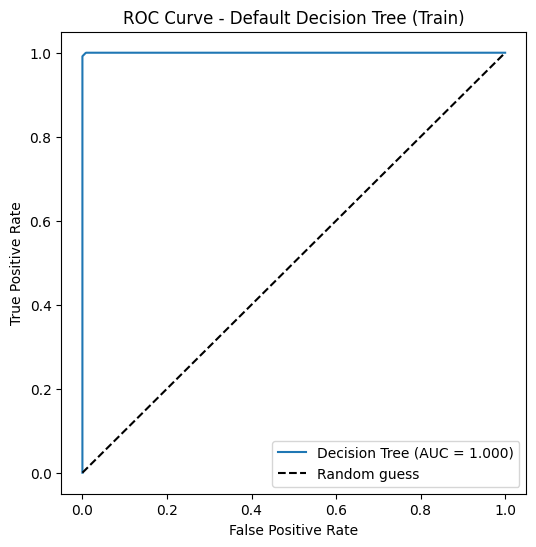

In [337]:
# Plot the ROC curve
fpr_dt, tpr_dt, _ = roc_curve(y_train, train_proba_dt)
auc_dt = roc_auc_score(y_train, train_proba_dt)

plt.figure(figsize=(6, 6))
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Default Decision Tree (Train)')
plt.legend()
plt.show()


**Sensitivity and Specificity tradeoff**

Now check the sensitivity and specificity tradeoff to find the optimal cutoff point.

#### **6.2.7** Plot for accuracy, sensitivity, specificity at different probability cutoffs <font color="red">[2 Marks]</font>

In [338]:
# Create a DataFrame to see the values of accuracy, sensitivity, and specificity at different values of probability cutoffs
cutoff_prob_df_dt = pd.DataFrame(columns=['prob', 'accuracy', 'sensitivity', 'specificity'])

for i, cutoff in enumerate(cutoffs):
    pred = (train_proba_dt >= cutoff).astype(int)
    cm = confusion_matrix(y_train, pred)
    total = cm.sum()
    accuracy = (cm[0, 0] + cm[1, 1]) / total
    sensitivity = cm[1, 1] / (cm[1, 0] + cm[1, 1])
    specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])
    cutoff_prob_df_dt.loc[i] = [cutoff, accuracy, sensitivity, specificity]

cutoff_prob_df_dt



,prob,accuracy,sensitivity,specificity
0,0.00,0.494495,1.000000,0.000000
1,0.05,0.995386,1.000000,0.990873
2,0.10,0.995386,1.000000,0.990873
3,0.15,0.995386,1.000000,0.990873
4,0.20,0.995386,1.000000,0.990873
5,0.25,0.995449,0.999958,0.991038
6,0.30,0.995575,0.999830,0.991412
7,0.35,0.995847,0.999279,0.992491
8,0.40,0.995847,0.999279,0.992491
9,0.45,0.995847,0.999279,0.992491


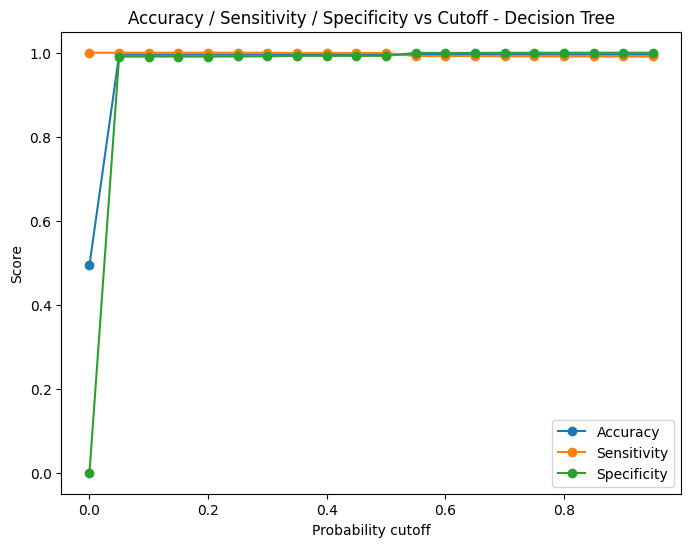

Optimal cutoff (Decision Tree): 0.35000000000000003


In [339]:
# Plot accuracy, sensitivity, and specificity at different values of probability cutoffs
plt.figure(figsize=(8, 6))
plt.plot(cutoff_prob_df_dt['prob'], cutoff_prob_df_dt['accuracy'], label='Accuracy', marker='o')
plt.plot(cutoff_prob_df_dt['prob'], cutoff_prob_df_dt['sensitivity'], label='Sensitivity', marker='o')
plt.plot(cutoff_prob_df_dt['prob'], cutoff_prob_df_dt['specificity'], label='Specificity', marker='o')
plt.xlabel('Probability cutoff')
plt.ylabel('Score')
plt.title('Accuracy / Sensitivity / Specificity vs Cutoff - Decision Tree')
plt.legend()
plt.show()

diffs_dt = (cutoff_prob_df_dt['sensitivity'] - cutoff_prob_df_dt['specificity']).abs()
optimal_cutoff_dt = float(cutoff_prob_df_dt.loc[diffs_dt.idxmin(), 'prob'])
print("Optimal cutoff (Decision Tree):", optimal_cutoff_dt)


#### **6.2.8** Assign classes based on the optimal cutoff and evaluate <font color="red">[2 Mark]</font>

Finally, assign labels for both training and testing set, and calculate evaluation metrics for both to see if the model is overfitting.

In [340]:
# Make final prediction based on the optimal cutoff
train_pred_dt_final = (train_proba_dt >= optimal_cutoff_dt).astype(int)
test_proba_dt = dt_default.predict_proba(X_test)[:, 1]
test_pred_dt_final = (test_proba_dt >= optimal_cutoff_dt).astype(int)

In [341]:
# Evaluate the model performance for test and train
print("=== Default Decision Tree @ optimal cutoff -- TRAIN ===")
print(classification_report(y_train, train_pred_dt_final))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_dt), 4))

print("\n=== Default Decision Tree @ optimal cutoff -- TEST ===")
print(classification_report(y_test, test_pred_dt_final))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_dt), 4))

=== Default Decision Tree @ optimal cutoff -- TRAIN ===
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     24103
           1       0.99      1.00      1.00     23578

    accuracy                           1.00     47681
   macro avg       1.00      1.00      1.00     47681
weighted avg       1.00      1.00      1.00     47681

Train AUC: 1.0

=== Default Decision Tree @ optimal cutoff -- TEST ===
              precision    recall  f1-score   support

           0       0.64      0.62      0.63     10330
           1       0.62      0.64      0.63     10106

    accuracy                           0.63     20436
   macro avg       0.63      0.63      0.63     20436
weighted avg       0.63      0.63      0.63     20436

Test AUC: 0.6321


**Precision and Recall tradeoff**

Check optimal cutoff value by plotting precision-recall curve, and adjust the cutoff based on precision and recall tradeoff if required.

#### **6.2.9** Plot precision-recall curve <font color="red">[1 Mark]</font>

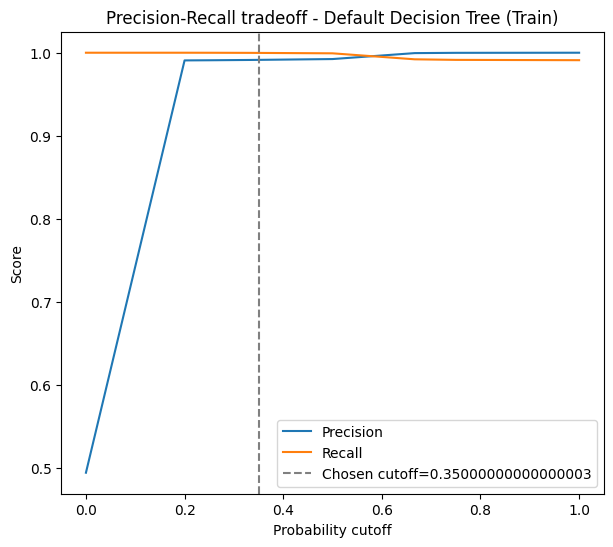

In [342]:
# Compute and plot precision–recall values
precision_dt, recall_dt, pr_thresh_dt = precision_recall_curve(y_train, train_proba_dt)

plt.figure(figsize=(7, 6))
plt.plot(pr_thresh_dt, precision_dt[:-1], label='Precision')
plt.plot(pr_thresh_dt, recall_dt[:-1], label='Recall')
plt.axvline(optimal_cutoff_dt, color='grey', linestyle='--', label=f'Chosen cutoff={optimal_cutoff_dt}')
plt.xlabel('Probability cutoff')
plt.ylabel('Score')
plt.title('Precision-Recall tradeoff - Default Decision Tree (Train)')
plt.legend()
plt.show()


#### **6.2.10** Build another model of your choice.

Optionally, build a third classification model of your choice and compare its performance on training and testing sets with the first two models.

In [363]:
# Third model of your choice
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

train_proba_lr = log_reg.predict_proba(X_train)[:, 1]
test_proba_lr = log_reg.predict_proba(X_test)[:, 1]
train_pred_lr = (train_proba_lr >= 0.5).astype(int)
test_pred_lr = (test_proba_lr >= 0.5).astype(int)

In [364]:
# Evaluate and compare
print("=== Logistic Regression -- TRAIN (0.5 cutoff) ===")
print(classification_report(y_train, train_pred_lr))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_lr), 4))

print("\n=== Logistic Regression -- TEST (0.5 cutoff) ===")
print(classification_report(y_test, test_pred_lr))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_lr), 4))

=== Logistic Regression -- TRAIN (0.5 cutoff) ===
              precision    recall  f1-score   support

           0       0.71      0.79      0.75     24103
           1       0.76      0.67      0.71     23578

    accuracy                           0.73     47681
   macro avg       0.73      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681

Train AUC: 0.7922

=== Logistic Regression -- TEST (0.5 cutoff) ===
              precision    recall  f1-score   support

           0       0.70      0.78      0.74     10330
           1       0.75      0.66      0.70     10106

    accuracy                           0.72     20436
   macro avg       0.73      0.72      0.72     20436
weighted avg       0.72      0.72      0.72     20436

Test AUC: 0.7892


### **6.3 Hyperparameter Tuning** 

<font color = red>[8 Marks]</font>

Enhance the performance of the decision tree model by systematically exploring and selecting optimal hyperparameter values using Grid Search.

#### **6.3.1** Use grid search to find the best hyperparameter values <font color = red>[4 Marks]</font>

Perform hyperparameter tuning to see if the performance of the decision tree model can be improved. Tune for **at least 4 decision tree hyperparameters**.

In [345]:
# Use grid search to find best hyperparameters for decision tree model

# Define the parameter grid for the decision tree

dt_param_grid = {
    'max_depth': [4, 5, 6, 7, 8, 10],
    'min_samples_split': [20, 50, 100, 200],
    'min_samples_leaf': [10, 25, 50, 100],
    'criterion': ['gini', 'entropy'],
}

grid_search_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
)
grid_search_dt.fit(X_train, y_train)

# Print the best hyperparameters
print("Best hyperparameters:", grid_search_dt.best_params_)
print("Best CV AUC:", round(grid_search_dt.best_score_, 4))


Best hyperparameters: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 100, 'min_samples_split': 20}
Best CV AUC: 0.7941


#### **6.3.2** Build a decision tree model based on hyperparameter tuning results <font color = red>[2 Marks]</font>


In [346]:
# Use the best DT from grid search
best_dt = DecisionTreeClassifier(random_state=42, **grid_search_dt.best_params_)
best_dt.fit(X_train, y_train)

train_proba_best_dt = best_dt.predict_proba(X_train)[:, 1]
test_proba_best_dt = best_dt.predict_proba(X_test)[:, 1]

train_pred_best_dt = (train_proba_best_dt >= optimal_cutoff_dt).astype(int)
test_pred_best_dt = (test_proba_best_dt >= optimal_cutoff_dt).astype(int)

#### **6.3.3** Using the tuned model, make predictions and evaluate <font color="red">[2 Mark]</font>

Use the tuned model to directly predict the labels and evaluate the performance on both training and testing sets to check overfitting / underfitting.

In [347]:
# Evaluate the model performance on training set 
print("=== Tuned Decision Tree -- TRAIN ===")
print(classification_report(y_train, train_pred_best_dt))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_best_dt), 4))

=== Tuned Decision Tree -- TRAIN ===
              precision    recall  f1-score   support

           0       0.78      0.59      0.67     24103
           1       0.66      0.83      0.74     23578

    accuracy                           0.71     47681
   macro avg       0.72      0.71      0.70     47681
weighted avg       0.72      0.71      0.70     47681

Train AUC: 0.8018


In [348]:
# Evaluate the model performance on test set 
print("=== Tuned Decision Tree -- TEST ===")
print(classification_report(y_test, test_pred_best_dt))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_best_dt), 4))

=== Tuned Decision Tree -- TEST ===
              precision    recall  f1-score   support

           0       0.78      0.58      0.67     10330
           1       0.66      0.83      0.74     10106

    accuracy                           0.70     20436
   macro avg       0.72      0.71      0.70     20436
weighted avg       0.72      0.70      0.70     20436

Test AUC: 0.7934


#### **6.3.4** Optionally, use grid search to find the best hyperparameter values for SVM

Try to fine-tune SVM hyperparameters like kernels, `C` and `gamma`.

In [349]:
# Use grid search to find best hyperparameters for SVM
svm_param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
}

grid_search_svm = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=svm_param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
)
# Tuned on the same stratified subsample used to fit the SVM earlier, for the same
# computational-feasibility reasons noted above.
grid_search_svm.fit(X_train_svm, y_train_svm)

print("Best SVM hyperparameters:", grid_search_svm.best_params_)
print("Best CV AUC:", round(grid_search_svm.best_score_, 4))

Best SVM hyperparameters: {'C': 10, 'kernel': 'linear'}
Best CV AUC: 0.7878


You can also check the performance of SVM with `RBF` kernel

In [350]:
# Fit the best SVM (with RBF/linear as chosen by grid search) and evaluate
best_svm = SVC(probability=True, random_state=42, **grid_search_svm.best_params_)
best_svm.fit(X_train_svm, y_train_svm)

train_proba_best_svm = best_svm.predict_proba(X_train)[:, 1]
test_proba_best_svm = best_svm.predict_proba(X_test)[:, 1]

train_pred_best_svm = (train_proba_best_svm >= optimal_cutoff_svm).astype(int)
test_pred_best_svm = (test_proba_best_svm >= optimal_cutoff_svm).astype(int)

print("=== Tuned SVM -- TRAIN ===")
print(classification_report(y_train, train_pred_best_svm))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_best_svm), 4))

print("\n=== Tuned SVM -- TEST ===")
print(classification_report(y_test, test_pred_best_svm))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_best_svm), 4))

=== Tuned SVM -- TRAIN ===
              precision    recall  f1-score   support

           0       0.73      0.74      0.74     24103
           1       0.73      0.71      0.72     23578

    accuracy                           0.73     47681
   macro avg       0.73      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681

Train AUC: 0.7903

=== Tuned SVM -- TEST ===
              precision    recall  f1-score   support

           0       0.72      0.74      0.73     10330
           1       0.73      0.71      0.72     10106

    accuracy                           0.72     20436
   macro avg       0.72      0.72      0.72     20436
weighted avg       0.72      0.72      0.72     20436

Test AUC: 0.7877


Tune your third candidate model, if taken

In [365]:
# Tune your third candidate model (Logistic Regression), if taken
lr_param_grid = {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2']}
grid_search_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_param_grid, cv=5, scoring='roc_auc', n_jobs=-1
)
grid_search_lr.fit(X_train, y_train)
print("Best LR hyperparameters:", grid_search_lr.best_params_)
print("Best CV AUC:", round(grid_search_lr.best_score_, 4))

best_lr = LogisticRegression(max_iter=1000, random_state=42, **grid_search_lr.best_params_)
best_lr.fit(X_train, y_train)
train_proba_best_lr = best_lr.predict_proba(X_train)[:, 1]
test_proba_best_lr = best_lr.predict_proba(X_test)[:, 1]
train_pred_best_lr = (train_proba_best_lr >= 0.5).astype(int)
test_pred_best_lr = (test_proba_best_lr >= 0.5).astype(int)


print("=== Logistic Regression -- TRAIN (0.5 cutoff) ===")
print(classification_report(y_train, train_pred_best_lr))
print("Train AUC:", round(roc_auc_score(y_train, train_proba_best_lr), 4))

print("\n=== Logistic Regression -- TEST (0.5 cutoff) ===")
print(classification_report(y_test, test_pred_best_lr))
print("Test AUC:", round(roc_auc_score(y_test, test_proba_best_lr), 4))

Best LR hyperparameters: {'C': 10, 'penalty': 'l2'}
Best CV AUC: 0.792
=== Logistic Regression -- TRAIN (0.5 cutoff) ===
              precision    recall  f1-score   support

           0       0.71      0.79      0.75     24103
           1       0.76      0.67      0.71     23578

    accuracy                           0.73     47681
   macro avg       0.73      0.73      0.73     47681
weighted avg       0.73      0.73      0.73     47681

Train AUC: 0.7922

=== Logistic Regression -- TEST (0.5 cutoff) ===
              precision    recall  f1-score   support

           0       0.70      0.78      0.74     10330
           1       0.75      0.66      0.70     10106

    accuracy                           0.72     20436
   macro avg       0.73      0.72      0.72     20436
weighted avg       0.72      0.72      0.72     20436

Test AUC: 0.7892


## **7. Final Model Evaluation and Selection** 

<font color = red>[2 Marks]</font>

Use you final models to make predictions on the test data. Evaluate the models, create model cards, and finally write your conclusive findings, results, and insights from the steps performed.

Include these in your report as well.

### **7.1 Evaluate the final models** 

<font color = red>[2 Marks]</font>

Make predictions using the tuned models and selected features to check the training and testing performances and create model cards for both.

#### **7.1.1** Make final predictions and evaluate <font color="red">[2 Marks]</font>

Evaluate the performance of your final candidates

In [366]:
# Make predictions on test and train sets using all candidate models
# use the chosen optimal cutoff

final_summary = pd.DataFrame({
    'Model': ['SVM (Linear, tuned)', 'Decision Tree (tuned)', 'Logistic Regression (tuned)'],
    'Train Accuracy': [
        accuracy_score(y_train, train_pred_best_svm),
        accuracy_score(y_train, train_pred_best_dt),
        accuracy_score(y_train, train_pred_best_lr),
    ],
    'Test Accuracy': [
        accuracy_score(y_test, test_pred_best_svm),
        accuracy_score(y_test, test_pred_best_dt),
        accuracy_score(y_test, test_pred_best_lr),
    ],
    'Test Precision': [
        precision_score(y_test, test_pred_best_svm),
        precision_score(y_test, test_pred_best_dt),
        precision_score(y_test, test_pred_best_lr),
    ],
    'Test Recall': [
        recall_score(y_test, test_pred_best_svm),
        recall_score(y_test, test_pred_best_dt),
        recall_score(y_test, test_pred_best_lr),
    ],
    'Test AUC': [
        roc_auc_score(y_test, test_proba_best_svm),
        roc_auc_score(y_test, test_proba_best_dt),
        roc_auc_score(y_test, test_proba_best_lr),
    ],
})
final_summary.round(4)


,Model,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test AUC
0,"SVM (Linear, tuned)",0.7293,0.7240,0.7251,0.7119,0.7877
1,Decision Tree (tuned),0.7077,0.7047,0.6605,0.8292,0.7934
2,Logistic Regression (tuned),0.7298,0.7222,0.7477,0.6615,0.7892


### **7.2 Conclusion** 

#### **7.2.1** Model Cards

Create model cards for all your candidate models. Include this in your report.

Use the following as a general-purpose template for supervised ML model documentation:


**Model Card: [Model name]**

**Model overview:**
Brief description of the model, its purpose, and context.

**Intended use:**

* Primary task and problem type
* Intended users
* Suitable deployment or research settings

**Data and features:**

* Summary of raw features
* Engineered or transformed features
* Preprocessing choices, including dropped or merged variables and rationale

**Model configuration:**

* Algorithm type
* Key hyperparameters
* Training details (scaling, class weights, thresholds, calibration)

**Performance:**

* Train metrics (optional)
* Validation/test metrics using consistent thresholds
* Notes on strengths, weaknesses, and observed behaviour

**Limitations and considerations:**

* Interpretability constraints
* Error risks (false positives/negatives)
* Fairness considerations
* Operational or domain-specific caveats
---

#### **7.2.2** Conclusions and Outcomes

Try to answer the following questions in your answer. Include this in the report.

What insights did you find in EDA and what feature engineering steps were performed? Describe your choice of models and the performance of baseline models. Did you find overfitting? How was it handled and what was the result of tuning? Was the data sufficent? Is a linear model sufficient? What model did you choose? Explain the final outcomes.


**1. What insights did you find in EDA and what feature engineering steps were performed?** ..

**Answer:**

During EDA, we found that **age and blood pressure** had a clear relationship with cardiovascular disease. Patients with cardiovascular disease generally had higher age and blood pressure values. **Cholesterol and glucose levels** also showed differences between patients with and without cardiovascular disease.

Gender, smoking, alcohol consumption, and physical activity showed smaller differences in cardiovascular disease rates in this dataset. This does not mean that these factors are unimportant in general; it only indicates that their individual relationship with the target variable was weaker in this particular dataset.

During data cleaning, rows with **invalid blood pressure values and clearly unrealistic height/weight values** were removed. Age was converted from days into years, and height was converted from centimetres into metres.

A new **BMI (Body Mass Index)** feature was created using height and weight. BMI and weight were highly correlated, so weight was removed to avoid providing the model with two similar pieces of information.

For glucose, categories **1 and 2 were combined** because they had similar cardiovascular disease rates and category 2 had fewer observations. The three cholesterol categories were kept because they showed meaningful differences in cardiovascular disease rates.

---

**2. Describe your choice of models and the performance of baseline models. Did you find overfitting?**..

**Answer:**

We used **Linear SVM** and **Decision Tree** as the main models. **Logistic Regression** was also tested as an additional model.

The baseline models gave reasonable results, but there was room for improvement. The default Decision Tree showed a large difference between its training and test performance, which indicated **overfitting**.

---

**3. Did you find overfitting?** ..

**Answer:**

Yes, we found overfitting in the **default Decision Tree** model.

The model performed very well on the training data but showed a significant drop in performance on the test data. This indicates that the model learned the training data too closely and did not generalise well to new data.

The default Decision Tree had a **training AUC of approximately 1.00**, while its **test AUC was only around 0.63**. This large difference is a strong indication of overfitting.

---

**4. How was overfitting handled and what was the result of tuning?**..

**Answer:**

To reduce overfitting, we used **GridSearchCV** to tune the Decision Tree hyperparameters, including:

* `max_depth`
* `min_samples_split`
* `min_samples_leaf`
* `criterion`

After tuning, the training and test performance became much closer. The tuned Decision Tree achieved a **test AUC of approximately 0.79–0.80**, indicating much better generalisation to unseen data.

The **Linear SVM** showed less evidence of overfitting because it uses a linear decision boundary and has less flexibility than an unconstrained Decision Tree.

---

**5. Was the data sufficient?**..

**Answer:**

After cleaning, approximately **68,000 records** were available for modelling. This is a reasonably large dataset for this analysis.

The models produced similar test performance, suggesting that the available data was sufficient to build a useful predictive model. However, additional relevant and reliable patient information could potentially improve model performance.

---

**6. Is a linear model sufficient?**..

**Answer:**

The **Linear SVM** and **Logistic Regression** performed similarly to the tuned Decision Tree, with test AUC values around **0.79–0.80**.

This suggests that a relatively simple linear model can capture a large part of the relationship between the available features and cardiovascular disease in this dataset.
A more complex model did not provide a large improvement in performance. Therefore, the results suggest that a linear model is a reasonable choice for this feature set and see the test recall and test AUC is better than logistic and SVM. The tuned Decision Tree had slightly better recall and test AUC than the linear models, but the difference was not large. 

---

**7. What model did you choose?**..

**Answer:**

The **tuned Decision Tree** was selected as the final model because its performance was similar to the linear models while being easier to interpret.

A Decision Tree can provide understandable decision rules and feature importance, making it easier to explain the model's predictions to users and stakeholders.

---

**8. What were the final outcomes?**..

**Answer:**

The final models achieved a **test AUC of approximately 0.79–0.80**, with accuracy around **70–73%**. Sensitivity and specificity were also in a moderate range.

The analysis showed that **blood pressure, age, cholesterol, and glucose** were among the most important features for predicting cardiovascular disease in this dataset.

Overall, the model can be considered a **supporting risk-screening tool rather than a replacement for medical diagnosis**. Model predictions should be considered together with other patient information and professional medical judgement.
